In [1]:
import pandas as pd
from pathlib import Path

DATABASE_DIR = Path("../../database")

matrix = pd.read_csv(
    DATABASE_DIR / "disease_symptom_matrix.csv"
)

print("Dataset shape:", matrix.shape)

Dataset shape: (34, 153)


In [2]:
feature_columns = [
    col for col in matrix.columns
    if col not in ["disease_id", "disease_name"]
]

X = matrix[feature_columns].copy()
y = matrix["disease_name"].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Number of features:", X.shape[1])
print("Number of diseases:", y.nunique())

X shape: (34, 151)
y shape: (34,)
Number of features: 151
Number of diseases: 34


In [3]:
print("Missing values:", X.isna().sum().sum())
print("Unique feature values:", sorted(X.stack().unique()))
print("Duplicate feature rows:", X.duplicated().sum())

Missing values: 0
Unique feature values: [np.int64(0), np.int64(1)]
Duplicate feature rows: 0


In [4]:
import numpy as np

np.random.seed(42)

SAMPLES_PER_DISEASE = 30

synthetic_X = []
synthetic_y = []

for index, row in X.iterrows():

    disease = y.iloc[index]
    original_profile = row.values.astype(int)

    for _ in range(SAMPLES_PER_DISEASE):

        sample = original_profile.copy()

        positive_indices = np.where(sample == 1)[0]

        # Hide approximately 20–40% of the known symptoms
        if len(positive_indices) > 1:

            dropout_rate = np.random.uniform(0.20, 0.40)

            number_to_hide = max(
                1,
                int(len(positive_indices) * dropout_rate)
            )

            hide_indices = np.random.choice(
                positive_indices,
                size=number_to_hide,
                replace=False
            )

            sample[hide_indices] = 0

        synthetic_X.append(sample)
        synthetic_y.append(disease)

synthetic_X = pd.DataFrame(
    synthetic_X,
    columns=feature_columns
)

synthetic_y = pd.Series(
    synthetic_y,
    name="disease"
)

print("Synthetic X shape:", synthetic_X.shape)
print("Synthetic y shape:", synthetic_y.shape)
print("Number of disease classes:", synthetic_y.nunique())

Synthetic X shape: (1020, 151)
Synthetic y shape: (1020,)
Number of disease classes: 34


In [5]:
print("Missing values:", synthetic_X.isna().sum().sum())

print(
    "Unique feature values:",
    sorted(synthetic_X.stack().unique())
)

print(
    "Duplicate rows:",
    synthetic_X.duplicated().sum()
)

print("\nSamples per disease:")
print(synthetic_y.value_counts().sort_index())

Missing values: 0
Unique feature values: [np.int64(0), np.int64(1)]
Duplicate rows: 434

Samples per disease:
disease
AIDS                                            30
Acne                                            30
Anxiety Disorder                                30
Asthma                                          30
COVID-19/Flu                                    30
Chickenpox                                      30
Chikungunya                                     30
Cholera                                         30
Chronic Obstructive Pulmonary Disease (COPD)    30
Common Cold                                     30
Dental caries (tooth Decay)                     30
Depression and Anxiety Disorder                 30
Diabetes                                        30
Gallstones                                      30
Gastroenteritis (Stomach flu)                   30
HIV                                             30
Heart Disease                                   30
Hypertension   

In [6]:
print("Number of diseases:", synthetic_y.nunique())
print("Total samples:", len(synthetic_y))

print("\nSamples per disease:")
print(synthetic_y.value_counts().sort_index())

Number of diseases: 34
Total samples: 1020

Samples per disease:
disease
AIDS                                            30
Acne                                            30
Anxiety Disorder                                30
Asthma                                          30
COVID-19/Flu                                    30
Chickenpox                                      30
Chikungunya                                     30
Cholera                                         30
Chronic Obstructive Pulmonary Disease (COPD)    30
Common Cold                                     30
Dental caries (tooth Decay)                     30
Depression and Anxiety Disorder                 30
Diabetes                                        30
Gallstones                                      30
Gastroenteritis (Stomach flu)                   30
HIV                                             30
Heart Disease                                   30
Hypertension                                    30
Impetigo 

In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    synthetic_X,
    synthetic_y,
    test_size=0.20,
    random_state=42,
    stratify=synthetic_y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining classes:", y_train.nunique())
print("Testing classes:", y_test.nunique())

Training samples: 816
Testing samples: 204

Training classes: 34
Testing classes: 34


In [8]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    class_weight="balanced"
)

rf_model.fit(X_train, y_train)

print("Random Forest training completed.")

Random Forest training completed.


In [9]:
from sklearn.metrics import accuracy_score, classification_report

# Make predictions on the test set
y_pred = rf_model.predict(X_test)

# Accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Random Forest Accuracy:", accuracy)
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Random Forest Accuracy: 0.9852941176470589

Classification Report:
                                              precision    recall  f1-score   support

                                        AIDS       0.80      0.67      0.73         6
                                        Acne       1.00      1.00      1.00         6
                            Anxiety Disorder       1.00      1.00      1.00         6
                                      Asthma       1.00      1.00      1.00         6
                                COVID-19/Flu       1.00      1.00      1.00         6
                                  Chickenpox       1.00      1.00      1.00         6
                                 Chikungunya       1.00      1.00      1.00         6
                                     Cholera       1.00      1.00      1.00         6
Chronic Obstructive Pulmonary Disease (COPD)       1.00      1.00      1.00         6
                                 Common Cold       1.00      1.00      1

In [10]:
# Check whether identical feature rows appear in both train and test sets

train_rows = set(map(tuple, X_train.to_numpy()))
test_rows = set(map(tuple, X_test.to_numpy()))

overlap = train_rows.intersection(test_rows)

print("Unique training feature rows:", len(train_rows))
print("Unique testing feature rows:", len(test_rows))
print("Identical feature rows in both train and test:", len(overlap))

Unique training feature rows: 509
Unique testing feature rows: 175
Identical feature rows in both train and test: 98


In [11]:
# Check whether identical symptom patterns have different disease labels

feature_cols = list(synthetic_X.columns)

group_label_counts = (
    pd.concat([synthetic_X, synthetic_y.rename("disease")], axis=1)
    .groupby(feature_cols)["disease"]
    .nunique()
)

print("Total unique feature patterns:", len(group_label_counts))
print(
    "Feature patterns linked to multiple diseases:",
    (group_label_counts > 1).sum()
)
print(
    "Maximum number of diseases for one feature pattern:",
    group_label_counts.max()
)


Total unique feature patterns: 586
Feature patterns linked to multiple diseases: 2
Maximum number of diseases for one feature pattern: 2


In [12]:
# Find symptom patterns associated with multiple diseases

ambiguous_patterns = (
    pd.concat([synthetic_X, synthetic_y.rename("disease")], axis=1)
    .groupby(feature_cols)["disease"]
    .unique()
)

ambiguous_patterns = ambiguous_patterns[
    ambiguous_patterns.apply(len) > 1
]

print("Number of ambiguous patterns:", len(ambiguous_patterns))

for i, (pattern, diseases) in enumerate(ambiguous_patterns.items(), 1):
    print(f"\nAmbiguous pattern {i}:")
    print("Diseases:", list(diseases))

Number of ambiguous patterns: 2

Ambiguous pattern 1:
Diseases: ['AIDS', 'HIV']

Ambiguous pattern 2:
Diseases: ['AIDS', 'HIV']


In [15]:
from sklearn.model_selection import StratifiedGroupKFold

# Create a group for every unique symptom pattern
groups = synthetic_X.astype(str).agg("|".join, axis=1)

# Stratified + group-aware splitting
sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

selected_split = None

for fold, (train_idx, test_idx) in enumerate(
    sgkf.split(synthetic_X, synthetic_y, groups)
):
    test_classes = synthetic_y.iloc[test_idx].nunique()

    print(
        f"Fold {fold + 1}: "
        f"train={len(train_idx)}, "
        f"test={len(test_idx)}, "
        f"test_classes={test_classes}"
    )

    if test_classes == synthetic_y.nunique():
        selected_split = (train_idx, test_idx)
        print("-> Selected this fold")
        break

if selected_split is None:
    raise ValueError(
        "Could not find a split containing all disease classes in the test set."
    )

train_idx, test_idx = selected_split

X_train = synthetic_X.iloc[train_idx].copy()
X_test = synthetic_X.iloc[test_idx].copy()

y_train = synthetic_y.iloc[train_idx].copy()
y_test = synthetic_y.iloc[test_idx].copy()

print("\nFinal split:")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Training classes:", y_train.nunique())
print("Testing classes:", y_test.nunique())

Fold 1: train=814, test=206, test_classes=34
-> Selected this fold

Final split:
Training samples: 814
Testing samples: 206
Training classes: 34
Testing classes: 34


In [16]:
# Verify that no identical symptom patterns exist in both train and test

train_rows = set(map(tuple, X_train.to_numpy()))
test_rows = set(map(tuple, X_test.to_numpy()))

overlap = train_rows.intersection(test_rows)

print("Unique training feature rows:", len(train_rows))
print("Unique testing feature rows:", len(test_rows))
print("Identical feature rows in both train and test:", len(overlap))

# Check which disease classes are missing from the test set
missing_test_classes = sorted(set(y_train.unique()) - set(y_test.unique()))

print("\nDiseases missing from test set:", len(missing_test_classes))
print(missing_test_classes)

Unique training feature rows: 468
Unique testing feature rows: 118
Identical feature rows in both train and test: 0

Diseases missing from test set: 0
[]


In [17]:
from sklearn.ensemble import RandomForestClassifier

# Create the Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest training completed.")

Random Forest training completed.


In [18]:
from sklearn.metrics import accuracy_score, classification_report

# Make predictions on the test set
y_pred = rf_model.predict(X_test)

# Accuracy
accuracy = accuracy_score(y_test, y_pred)

print(f"Random Forest Accuracy: {accuracy:.4f}")

# Detailed classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Random Forest Accuracy: 0.9951

Classification Report:
                                              precision    recall  f1-score   support

                                        AIDS       0.86      1.00      0.92         6
                                        Acne       1.00      1.00      1.00         6
                            Anxiety Disorder       1.00      1.00      1.00         6
                                      Asthma       1.00      1.00      1.00         6
                                COVID-19/Flu       1.00      1.00      1.00         6
                                  Chickenpox       1.00      1.00      1.00         6
                                 Chikungunya       1.00      1.00      1.00         6
                                     Cholera       1.00      1.00      1.00         5
Chronic Obstructive Pulmonary Disease (COPD)       1.00      1.00      1.00         6
                                 Common Cold       1.00      1.00      1.00         

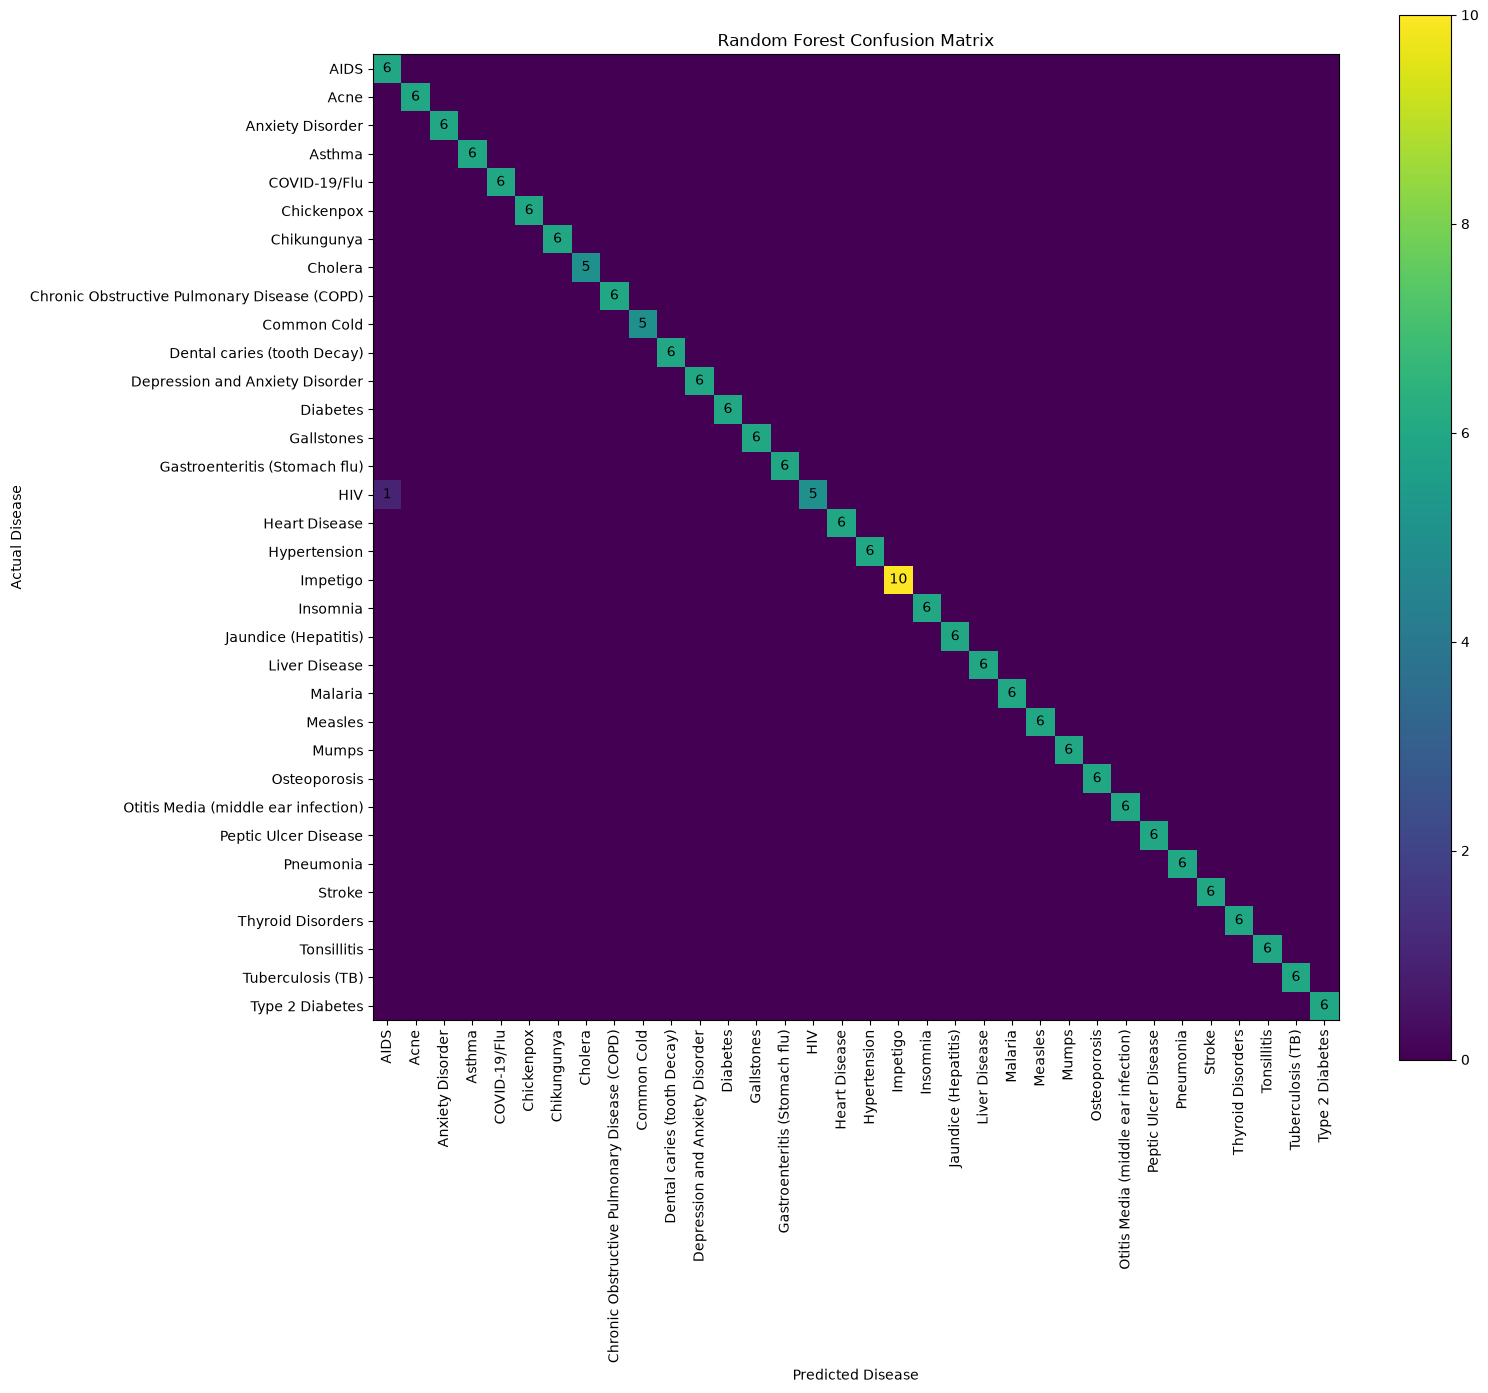

In [20]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=rf_model.classes_)

plt.figure(figsize=(16, 14))

plt.imshow(cm, interpolation="nearest")
plt.title("Random Forest Confusion Matrix")
plt.colorbar()

# Axis labels
plt.xlabel("Predicted Disease")
plt.ylabel("Actual Disease")

# Disease names
classes = rf_model.classes_
plt.xticks(range(len(classes)), classes, rotation=90)
plt.yticks(range(len(classes)), classes)

# Show numbers inside the matrix
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        if cm[i, j] != 0:
            plt.text(j, i, cm[i, j], ha="center", va="center")

plt.tight_layout()
plt.show()

Top 20 most important symptoms:
    Symptom  Importance
48     S049    0.020782
59     S060    0.016856
63     S064    0.015400
104    S105    0.014790
80     S081    0.014505
69     S070    0.013822
108    S109    0.013412
57     S058    0.013378
82     S083    0.013328
137    S138    0.013317
3      S004    0.013268
37     S038    0.013032
127    S128    0.013025
66     S067    0.012778
73     S074    0.012736
38     S039    0.011768
49     S050    0.011758
95     S096    0.011172
123    S124    0.011153
99     S100    0.011116


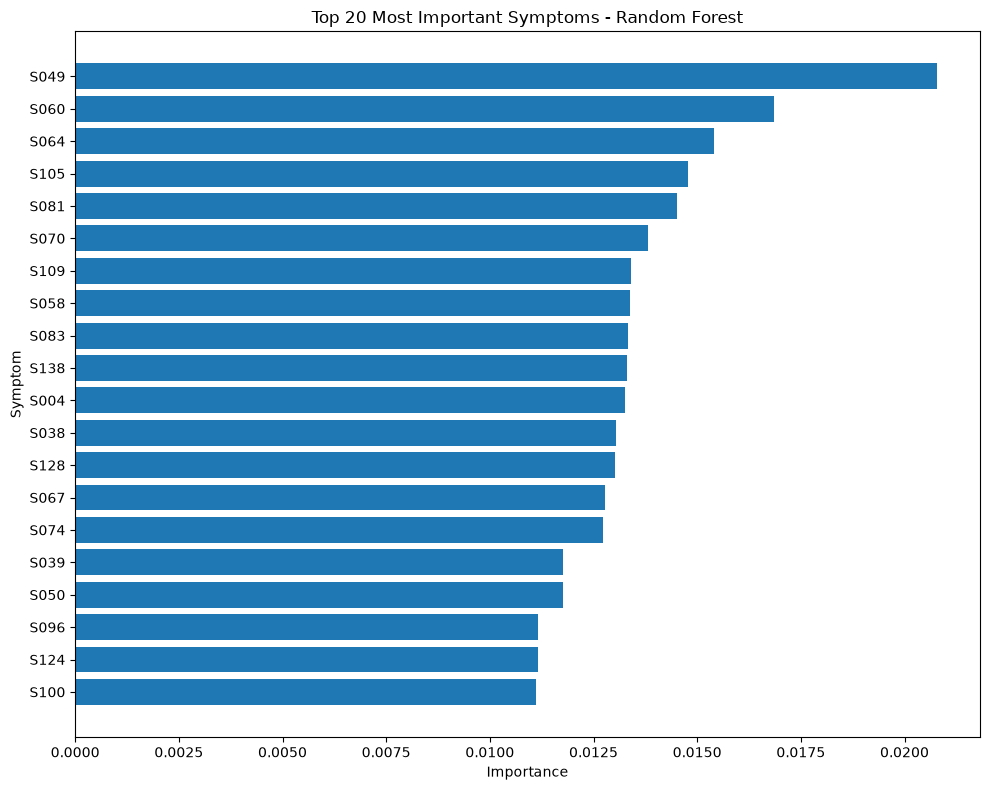

In [21]:
import pandas as pd
import matplotlib.pyplot as plt

# Get feature importance from Random Forest
feature_importance = pd.DataFrame({
    "Symptom": X_train.columns,
    "Importance": rf_model.feature_importances_
})

# Sort from most important to least important
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Top 20 most important symptoms:")
print(feature_importance.head(20))

# Plot top 20 features
top_features = feature_importance.head(20).sort_values(
    by="Importance"
)

plt.figure(figsize=(10, 8))
plt.barh(
    top_features["Symptom"],
    top_features["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Symptom")
plt.title("Top 20 Most Important Symptoms - Random Forest")
plt.tight_layout()
plt.show()

In [22]:
import joblib
import os

# Make sure the model directory exists
os.makedirs("../models", exist_ok=True)

# Save model + feature information together
model_bundle = {
    "model": rf_model,
    "features": list(X_train.columns),
    "classes": list(rf_model.classes_)
}

# Save the bundle
model_path = "../models/disease_random_forest.pkl"
joblib.dump(model_bundle, model_path)

print("Model saved successfully!")
print("Path:", model_path)
print("Number of features:", len(X_train.columns))
print("Number of classes:", len(rf_model.classes_))

Model saved successfully!
Path: ../models/disease_random_forest.pkl
Number of features: 151
Number of classes: 34


In [23]:
import joblib

# Load the saved model bundle
loaded_bundle = joblib.load("../models/disease_random_forest.pkl")

loaded_model = loaded_bundle["model"]
loaded_features = loaded_bundle["features"]
loaded_classes = loaded_bundle["classes"]

print("Model loaded successfully!")
print("Features:", len(loaded_features))
print("Classes:", len(loaded_classes))
print("Model type:", type(loaded_model).__name__)

Model loaded successfully!
Features: 151
Classes: 34
Model type: RandomForestClassifier


In [24]:
print("Number of features:", len(loaded_features))
print("\nFeature names:")
print(loaded_features)

Number of features: 151

Feature names:
['S001', 'S002', 'S003', 'S004', 'S005', 'S006', 'S007', 'S008', 'S009', 'S010', 'S011', 'S012', 'S013', 'S014', 'S015', 'S016', 'S017', 'S018', 'S019', 'S020', 'S021', 'S022', 'S023', 'S024', 'S025', 'S026', 'S027', 'S028', 'S029', 'S030', 'S031', 'S032', 'S033', 'S034', 'S035', 'S036', 'S037', 'S038', 'S039', 'S040', 'S041', 'S042', 'S043', 'S044', 'S045', 'S046', 'S047', 'S048', 'S049', 'S050', 'S051', 'S052', 'S053', 'S054', 'S055', 'S056', 'S057', 'S058', 'S059', 'S060', 'S061', 'S062', 'S063', 'S064', 'S065', 'S066', 'S067', 'S068', 'S069', 'S070', 'S071', 'S072', 'S073', 'S074', 'S075', 'S076', 'S077', 'S078', 'S079', 'S080', 'S081', 'S082', 'S083', 'S084', 'S085', 'S086', 'S087', 'S088', 'S089', 'S090', 'S091', 'S092', 'S093', 'S094', 'S095', 'S096', 'S097', 'S098', 'S099', 'S100', 'S101', 'S102', 'S103', 'S104', 'S105', 'S106', 'S107', 'S108', 'S109', 'S110', 'S111', 'S112', 'S113', 'S114', 'S115', 'S116', 'S117', 'S118', 'S119', 'S120',

In [25]:
for i, feature in enumerate(loaded_features):
    print(i, "→", feature)

0 → S001
1 → S002
2 → S003
3 → S004
4 → S005
5 → S006
6 → S007
7 → S008
8 → S009
9 → S010
10 → S011
11 → S012
12 → S013
13 → S014
14 → S015
15 → S016
16 → S017
17 → S018
18 → S019
19 → S020
20 → S021
21 → S022
22 → S023
23 → S024
24 → S025
25 → S026
26 → S027
27 → S028
28 → S029
29 → S030
30 → S031
31 → S032
32 → S033
33 → S034
34 → S035
35 → S036
36 → S037
37 → S038
38 → S039
39 → S040
40 → S041
41 → S042
42 → S043
43 → S044
44 → S045
45 → S046
46 → S047
47 → S048
48 → S049
49 → S050
50 → S051
51 → S052
52 → S053
53 → S054
54 → S055
55 → S056
56 → S057
57 → S058
58 → S059
59 → S060
60 → S061
61 → S062
62 → S063
63 → S064
64 → S065
65 → S066
66 → S067
67 → S068
68 → S069
69 → S070
70 → S071
71 → S072
72 → S073
73 → S074
74 → S075
75 → S076
76 → S077
77 → S078
78 → S079
79 → S080
80 → S081
81 → S082
82 → S083
83 → S084
84 → S085
85 → S086
86 → S087
87 → S088
88 → S089
89 → S090
90 → S091
91 → S092
92 → S093
93 → S094
94 → S095
95 → S096
96 → S097
97 → S098
98 → S099
99 → S100
100 → S101

In [26]:
import pandas as pd
import numpy as np

def predict_disease(selected_symptoms):
    """
    Predict disease from a list of symptom feature names.
    
    Example:
    predict_disease(["S049", "S060", "S064"])
    """

    # Create an empty feature vector
    input_data = pd.DataFrame(
        np.zeros((1, len(loaded_features))),
        columns=loaded_features
    )

    # Activate the selected symptoms
    for symptom in selected_symptoms:
        if symptom in input_data.columns:
            input_data.loc[0, symptom] = 1
        else:
            print(f"Warning: {symptom} is not a valid feature.")

    # Predict disease
    prediction = loaded_model.predict(input_data)[0]

    # Get probabilities
    probabilities = loaded_model.predict_proba(input_data)[0]

    # Find confidence of predicted disease
    predicted_index = list(loaded_classes).index(prediction)
    confidence = probabilities[predicted_index]

    return prediction, confidence

In [27]:
result, confidence = predict_disease(["S049", "S060", "S064"])

print("Predicted disease:", result)
print("Confidence:", round(confidence * 100, 2), "%")

Predicted disease: Cholera
Confidence: 46.0 %


In [28]:
print(synthetic_X.columns.tolist())

['S001', 'S002', 'S003', 'S004', 'S005', 'S006', 'S007', 'S008', 'S009', 'S010', 'S011', 'S012', 'S013', 'S014', 'S015', 'S016', 'S017', 'S018', 'S019', 'S020', 'S021', 'S022', 'S023', 'S024', 'S025', 'S026', 'S027', 'S028', 'S029', 'S030', 'S031', 'S032', 'S033', 'S034', 'S035', 'S036', 'S037', 'S038', 'S039', 'S040', 'S041', 'S042', 'S043', 'S044', 'S045', 'S046', 'S047', 'S048', 'S049', 'S050', 'S051', 'S052', 'S053', 'S054', 'S055', 'S056', 'S057', 'S058', 'S059', 'S060', 'S061', 'S062', 'S063', 'S064', 'S065', 'S066', 'S067', 'S068', 'S069', 'S070', 'S071', 'S072', 'S073', 'S074', 'S075', 'S076', 'S077', 'S078', 'S079', 'S080', 'S081', 'S082', 'S083', 'S084', 'S085', 'S086', 'S087', 'S088', 'S089', 'S090', 'S091', 'S092', 'S093', 'S094', 'S095', 'S096', 'S097', 'S098', 'S099', 'S100', 'S101', 'S102', 'S103', 'S104', 'S105', 'S106', 'S107', 'S108', 'S109', 'S110', 'S111', 'S112', 'S113', 'S114', 'S115', 'S116', 'S117', 'S118', 'S119', 'S120', 'S121', 'S122', 'S123', 'S124', 'S125',

In [29]:
from pathlib import Path

print("CSV files found in the project:\n")

for file in Path(".").rglob("*.csv"):
    print(file)

CSV files found in the project:



In [30]:
import os
from pathlib import Path

print("Current working directory:")
print(os.getcwd())

print("\nProject data folder:")
data_path = Path("/workspaces/SIH-PROJECT/data")

if data_path.exists():
    for file in data_path.rglob("*"):
        if file.is_file():
            print(file)
else:
    print("Data folder not found.")

Current working directory:
/workspaces/SIH-PROJECT/ml/notebooks

Project data folder:
/workspaces/SIH-PROJECT/data/vaccitnations.js
/workspaces/SIH-PROJECT/data/medicineInfo.js
/workspaces/SIH-PROJECT/data/healthFacilities.js
/workspaces/SIH-PROJECT/data/biology.js
/workspaces/SIH-PROJECT/data/symptoms.js
/workspaces/SIH-PROJECT/data/firstAid.js
/workspaces/SIH-PROJECT/data/reminders.js


In [31]:
import pandas as pd

# Load symptom information
symptoms_df = pd.read_csv("../../database/symptoms.csv")

# Create symptom name → symptom ID mapping
symptom_name_to_id = dict(
    zip(symptoms_df["symptom_name"], symptoms_df["symptom_id"])
)

print("Symptoms loaded:", len(symptom_name_to_id))

Symptoms loaded: 151


In [32]:
print(symptom_name_to_id["Tiredness or fatigue"])

S004


In [33]:
selected_symptoms = [
    "Tiredness or fatigue",
    "Shortness of breath",
    "Frequent urination"
]

selected_ids = [
    symptom_name_to_id[symptom]
    for symptom in selected_symptoms
]

print("Selected symptom IDs:", selected_ids)

Selected symptom IDs: ['S004', 'S005', 'S008']


In [34]:
result, confidence = predict_disease(selected_ids)

print("Predicted disease:", result)
print("Confidence:", round(confidence * 100, 2), "%")

Predicted disease: Diabetes
Confidence: 19.67 %


In [35]:
def predict_top_diseases(symptom_ids, top_n=3):
    # Create an empty feature vector
    input_data = pd.DataFrame(
        0,
        index=[0],
        columns=loaded_features
    )

    # Activate selected symptoms
    for symptom_id in symptom_ids:
        if symptom_id in input_data.columns:
            input_data.loc[0, symptom_id] = 1

    # Get probabilities for all diseases
    probabilities = loaded_model.predict_proba(input_data)[0]

    # Get indices of highest probabilities
    top_indices = probabilities.argsort()[-top_n:][::-1]

    results = []

    for index in top_indices:
        results.append({
            "disease": loaded_classes[index],
            "confidence": probabilities[index]
        })

    return results

In [36]:
top_predictions = predict_top_diseases(selected_ids, top_n=3)

for i, prediction in enumerate(top_predictions, 1):
    print(
        f"{i}. {prediction['disease']} - "
        f"{prediction['confidence'] * 100:.2f}%"
    )

1. Diabetes - 19.67%
2. Pneumonia - 16.00%
3. Chronic Obstructive Pulmonary Disease (COPD) - 14.67%
